# Raw Exploration 
# Raw Notebook

**Project:** AI-Powered Energy Consumption Forecasting & Anomaly Detection System

This notebook keeps the original, end-to-end development work exactly as it was built -- the duplicate-timestamp investigation, the full single-house (Karachi House 38) pipeline, and the 18-house/6-city scale-up. It is kept separate from the cleaned, split notebooks (`01` through `07`) so the debugging and problem-solving process stays visible.

For a clean, documented, step-by-step version of this same work, see notebooks `01_data_cleaning_and_eda.ipynb` through `07_weather_enhanced_forecasting.ipynb`.

**Note:** this notebook is the original development history. It contains the *first* version of the pipeline (before the later fixes: rolling features without leakage, a separate validation set for the anomaly threshold, baselines, a day-ahead model). Use notebooks `01`–`07` for the final results.

In [ ]:
import pandas as pd
data_root = "/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House38.csv"
raw_df = pd.read_csv(data_root)

raw_time = raw_df["datetime"].astype(str)

new_datetime = []

i = 0

while i < len(raw_df):

    current = raw_time.iloc[i]

    # Count how many consecutive rows have the exact same timestamp
    j = i + 1
    while j < len(raw_df) and raw_time.iloc[j] == current:
        j += 1

    count = j - i

    # Convert the current timestamp
    base_time = pd.to_datetime(current, format="mixed")

    # If timestamp is repeated, assign seconds
    for second in range(count):
        new_datetime.append(
            base_time + pd.Timedelta(seconds=second)
        )

    i = j

df = raw_df.copy()
df["datetime"] = new_datetime

In [110]:
print(
    df.loc[478790:479050, ["datetime", "Usage (kW)"]]
    .to_string(index=True)
)

                  datetime  Usage (kW)
478790 2024-07-30 23:57:00    0.393867
478791 2024-07-30 23:58:00    0.395667
478792 2024-07-30 23:59:00    0.397900
478793 2024-07-31 00:00:00    0.318483
478794 2024-07-31 00:00:01    0.317650
478795 2024-07-31 00:00:02    0.319950
478796 2024-07-31 00:00:03    0.321067
478797 2024-07-31 00:00:04    0.321333
478798 2024-07-31 00:00:05    0.321300
478799 2024-07-31 00:00:06    0.319617
478800 2024-07-31 00:00:07    0.318067
478801 2024-07-31 00:00:08    0.329200
478802 2024-07-31 00:00:09    0.325483
478803 2024-07-31 00:00:10    0.326500
478804 2024-07-31 00:00:11    0.327350
478805 2024-07-31 00:00:12    0.326350
478806 2024-07-31 00:00:13    0.326033
478807 2024-07-31 00:00:14    0.326250
478808 2024-07-31 00:00:15    0.327200
478809 2024-07-31 00:00:16    0.327250
478810 2024-07-31 00:00:17    0.327250
478811 2024-07-31 00:00:18    0.327033
478812 2024-07-31 00:00:19    0.326083
478813 2024-07-31 00:00:20    0.327167
478814 2024-07-31 00:00:2

In [111]:
print("Duplicate datetime:", df["datetime"].duplicated().sum())

Duplicate datetime: 0


In [112]:
print(df["datetime"].diff().value_counts().head(15))

datetime
0 days 00:01:00    503125
0 days 00:00:01     23337
Name: count, dtype: int64


In [113]:
print("Sorted:", df["datetime"].is_monotonic_increasing)

Sorted: True


In [114]:
print("Missing datetime:", df["datetime"].isna().sum())

Missing datetime: 0


In [115]:
diffs = df["datetime"].diff()

print(diffs.value_counts().tail(20))

datetime
0 days 00:01:00    503125
0 days 00:00:01     23337
Name: count, dtype: int64


In [116]:
print("Gaps greater than 1 minute:")
print((diffs > pd.Timedelta(minutes=1)).sum())

print("\nLargest gaps:")
print(diffs.nlargest(10))

Gaps greater than 1 minute:
0

Largest gaps:
1    0 days 00:01:00
2    0 days 00:01:00
3    0 days 00:01:00
4    0 days 00:01:00
5    0 days 00:01:00
6    0 days 00:01:00
7    0 days 00:01:00
8    0 days 00:01:00
9    0 days 00:01:00
10   0 days 00:01:00
Name: datetime, dtype: timedelta64[ns]


In [117]:
print(df.isnull().sum())

datetime                        0
Usage (kW)                      0
Washing Machine (kW)        22945
BR_1_AC (kW)                22945
BR_2_AC (kW)                22945
Fridge + Water Pump (kW)    22945
Kitchen (kW)                22945
dtype: int64


In [118]:
print((df.isnull().sum() / len(df) * 100).round(2))

datetime                    0.00
Usage (kW)                  0.00
Washing Machine (kW)        4.36
BR_1_AC (kW)                4.36
BR_2_AC (kW)                4.36
Fridge + Water Pump (kW)    4.36
Kitchen (kW)                4.36
dtype: float64


In [120]:
import numpy as np
# Detect long streaks of 0.000000 (sensor downtime)
df['is_zero'] = df['Usage (kW)'] == 0
df['zero_streak'] = df['is_zero'].groupby((~df['is_zero']).cumsum()).cumsum()

# If 10+ consecutive minutes are zero, it's a sensor gap -- mark as NaN
suspicious = df['zero_streak'] >= 10
print(f"Suspicious zero-streak rows: {suspicious.sum()}")

df.loc[suspicious, 'Usage (kW)'] = np.nan

Suspicious zero-streak rows: 19444


In [121]:
# Set datetime as index for interpolation
df = df.set_index('datetime')

# Time-based interpolation fills the missing gaps
df['Usage (kW)'] = df['Usage (kW)'].interpolate(method='time')

# Check how much was filled
print("Remaining NaN:", df['Usage (kW)'].isna().sum())

df = df.reset_index()
df[['datetime', 'Usage (kW)']].iloc[478840:478920]

Remaining NaN: 0


,datetime,Usage (kW)
478840,2024-07-31 00:00:47,0.395533
478841,2024-07-31 00:00:48,0.396500
478842,2024-07-31 00:00:49,0.396950
478843,2024-07-31 00:00:50,0.397350
478844,2024-07-31 00:00:51,0.397050
...,...,...
478915,2024-07-31 01:00:03,0.326733
478916,2024-07-31 01:00:04,0.327717
478917,2024-07-31 01:00:05,0.328167
478918,2024-07-31 01:00:06,0.328500


In [122]:
# List of appliance columns available for house 38
usage_cols = ['Usage (kW)', 'Washing Machine (kW)', 'BR_1_AC (kW)', 
              'BR_2_AC (kW)', 'Fridge + Water Pump (kW)', 'Kitchen (kW)']

# Resample to hourly -- taking the mean
df = df.set_index('datetime')
hourly_df = df[usage_cols].resample('H').mean()
hourly_df = hourly_df.reset_index()

print(hourly_df.shape)
hourly_df.head(10)

(8393, 7)


/tmp/ipykernel_113/909540852.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  hourly_df = df[usage_cols].resample('H').mean()


,datetime,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW)
0,2023-09-02 12:00:00,0.526868,0.003235,0.004568,0.005349,0.153806,0.002909
1,2023-09-02 13:00:00,1.298505,0.004410,0.004978,0.004553,0.239058,0.002941
2,2023-09-02 14:00:00,1.857305,0.004286,0.004638,0.002990,0.205566,0.036126
3,2023-09-02 15:00:00,1.619104,0.002441,0.002962,0.002348,0.254719,0.001775
4,2023-09-02 16:00:00,1.593942,0.003102,0.002518,0.004691,0.225510,0.003807
5,2023-09-02 17:00:00,1.247060,0.003362,0.003612,0.004806,0.212079,0.004067
6,2023-09-02 18:00:00,0.860944,0.004059,0.001849,0.001523,0.272054,0.005031
7,2023-09-02 19:00:00,0.694312,0.004136,0.002584,0.000756,0.255406,0.005946
8,2023-09-02 20:00:00,1.022356,0.004642,0.002074,0.002569,0.257855,0.005972
9,2023-09-02 21:00:00,0.722148,0.004211,0.002536,0.000482,0.230938,0.005702


In [124]:
hourly_df = df[usage_cols].resample('h').mean()
hourly_df = hourly_df.reset_index()   # this line is required

print(hourly_df.columns.tolist())  # check whether 'datetime' is a column or still the index
hourly_df.head()

['datetime', 'Usage (kW)', 'Washing Machine (kW)', 'BR_1_AC (kW)', 'BR_2_AC (kW)', 'Fridge + Water Pump (kW)', 'Kitchen (kW)']


,datetime,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW)
0,2023-09-02 12:00:00,0.526868,0.003235,0.004568,0.005349,0.153806,0.002909
1,2023-09-02 13:00:00,1.298505,0.004410,0.004978,0.004553,0.239058,0.002941
2,2023-09-02 14:00:00,1.857305,0.004286,0.004638,0.002990,0.205566,0.036126
3,2023-09-02 15:00:00,1.619104,0.002441,0.002962,0.002348,0.254719,0.001775
4,2023-09-02 16:00:00,1.593942,0.003102,0.002518,0.004691,0.225510,0.003807


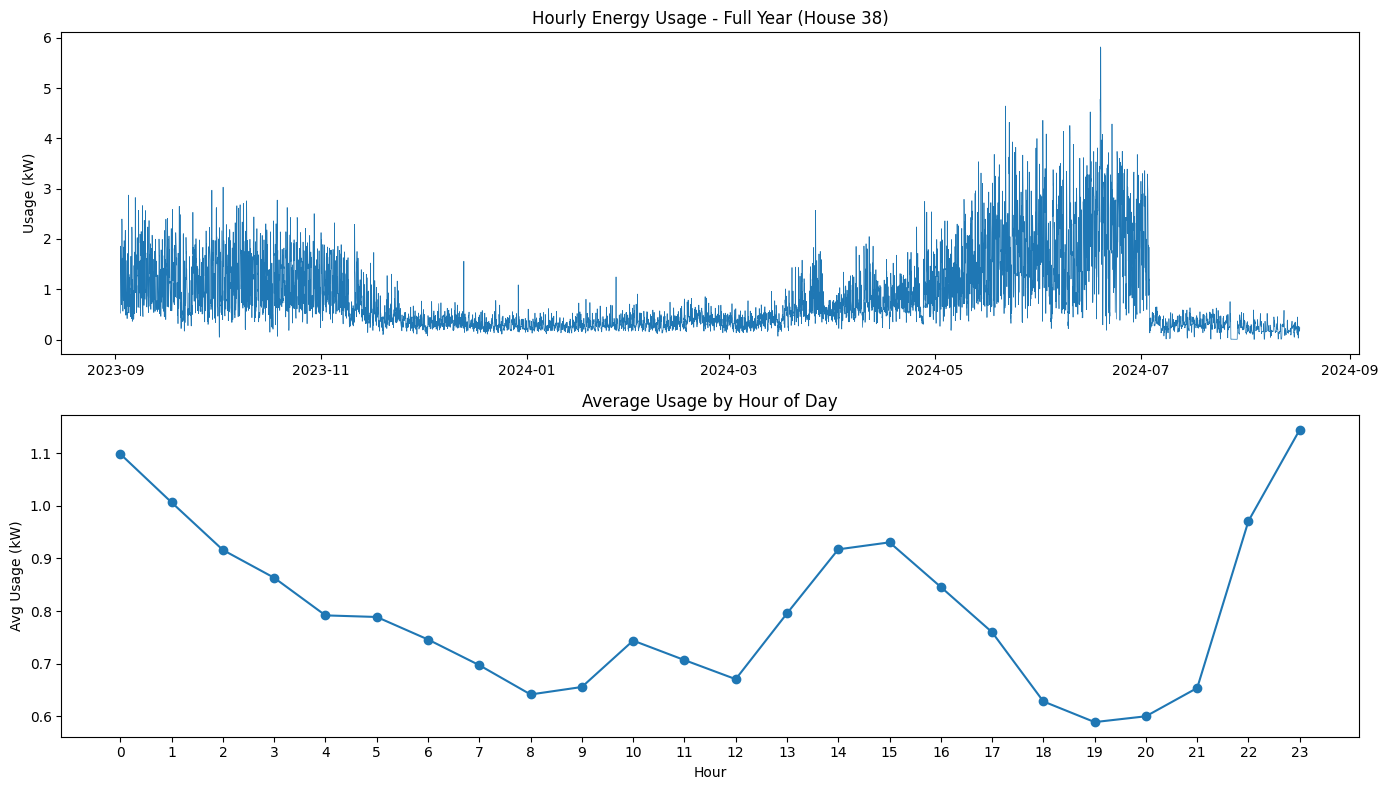

In [125]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# 1. Full-year trend
axes[0].plot(hourly_df['datetime'], hourly_df['Usage (kW)'], linewidth=0.5)
axes[0].set_title('Hourly Energy Usage - Full Year (House 38)')
axes[0].set_ylabel('Usage (kW)')

# 2. Average hourly pattern (when usage peaks during the 24-hour day)
hourly_df['hour'] = hourly_df['datetime'].dt.hour
avg_by_hour = hourly_df.groupby('hour')['Usage (kW)'].mean()

axes[1].plot(avg_by_hour.index, avg_by_hour.values, marker='o')
axes[1].set_title('Average Usage by Hour of Day')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('Avg Usage (kW)')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

In [126]:
print(hourly_df.tail(30)[['datetime', 'Usage (kW)']])

                datetime  Usage (kW)
8363 2024-08-15 23:00:00    0.340288
8364 2024-08-16 00:00:00    0.251876
8365 2024-08-16 01:00:00    0.213161
8366 2024-08-16 02:00:00    0.213717
8367 2024-08-16 03:00:00    0.213389
8368 2024-08-16 04:00:00    0.214475
8369 2024-08-16 05:00:00    0.220534
8370 2024-08-16 06:00:00    0.224987
8371 2024-08-16 07:00:00    0.259749
8372 2024-08-16 08:00:00    0.254011
8373 2024-08-16 09:00:00    0.126990
8374 2024-08-16 10:00:00    0.215586
8375 2024-08-16 11:00:00    0.096175
8376 2024-08-16 12:00:00    0.449175
8377 2024-08-16 13:00:00    0.095309
8378 2024-08-16 14:00:00    0.093240
8379 2024-08-16 15:00:00    0.152806
8380 2024-08-16 16:00:00    0.262851
8381 2024-08-16 17:00:00    0.030174
8382 2024-08-16 18:00:00    0.030787
8383 2024-08-16 19:00:00    0.030998
8384 2024-08-16 20:00:00    0.144960
8385 2024-08-16 21:00:00    0.266773
8386 2024-08-16 22:00:00    0.246127
8387 2024-08-16 23:00:00    0.246243
8388 2024-08-17 00:00:00    0.171248
8

In [127]:
# Time-based features
hourly_df['hour'] = hourly_df['datetime'].dt.hour
hourly_df['day_of_week'] = hourly_df['datetime'].dt.dayofweek
hourly_df['month'] = hourly_df['datetime'].dt.month

# Lag features -- past usage values
hourly_df['usage_lag_1hr'] = hourly_df['Usage (kW)'].shift(1)
hourly_df['usage_lag_24hr'] = hourly_df['Usage (kW)'].shift(24)   # same time, yesterday
hourly_df['usage_lag_168hr'] = hourly_df['Usage (kW)'].shift(168) # same time, last week

# Rolling average — recent trend
hourly_df['rolling_avg_24hr'] = hourly_df['Usage (kW)'].rolling(24).mean()

# Creating lags makes the first few rows NaN (no 168-hour history exists for them)
print("NaN rows after lag features:", hourly_df.isna().sum().sum())
hourly_df = hourly_df.dropna().reset_index(drop=True)
print("Final shape:", hourly_df.shape)

hourly_df.head()


NaN rows after lag features: 216
Final shape: (8225, 14)


,datetime,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW),hour,day_of_week,month,usage_lag_1hr,usage_lag_24hr,usage_lag_168hr,rolling_avg_24hr
0,2023-09-09 12:00:00,0.680853,0.001042,0.003248,0.001554,0.249992,0.004642,12,5,9,1.491336,0.598846,0.526868,1.337812
1,2023-09-09 13:00:00,0.790200,0.076941,0.001752,0.002237,0.177616,0.003181,13,5,9,0.680853,0.735010,1.298505,1.340112
2,2023-09-09 14:00:00,2.369217,0.031536,0.000933,0.002524,0.250141,0.007333,14,5,9,0.790200,2.089429,1.857305,1.351770
3,2023-09-09 15:00:00,2.200479,0.099456,0.002002,0.004011,0.436022,0.007376,15,5,9,2.369217,1.666164,1.619104,1.374033
4,2023-09-09 16:00:00,1.620764,0.006724,0.002289,0.005749,0.261379,0.005739,16,5,9,2.200479,2.147980,1.593942,1.352066


In [128]:
# 80% train, 20% test — chronological split
split_idx = int(len(hourly_df) * 0.8)

train_df = hourly_df.iloc[:split_idx]
test_df = hourly_df.iloc[split_idx:]

print("Train:", train_df.shape, train_df['datetime'].min(), "to", train_df['datetime'].max())
print("Test:", test_df.shape, test_df['datetime'].min(), "to", test_df['datetime'].max())

# Separate features and target
feature_cols = ['hour', 'day_of_week', 'month', 'usage_lag_1hr', 
                 'usage_lag_24hr', 'usage_lag_168hr', 'rolling_avg_24hr']
target_col = 'Usage (kW)'

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Train: (6580, 14) 2023-09-09 12:00:00 to 2024-06-09 15:00:00
Test: (1645, 14) 2024-06-09 16:00:00 to 2024-08-17 04:00:00

X_train shape: (6580, 7)
X_test shape: (1645, 7)


In [129]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Train the model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"MAPE: {mape:.2f}%")

# Check feature importance -- which feature contributes the most
importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\nFeature Importance:")
print(importance)

MAE: 0.2656 kW
RMSE: 0.4654 kW
MAPE: 161.08%

Feature Importance:
usage_lag_1hr       0.402636
rolling_avg_24hr    0.328355
usage_lag_24hr      0.113465
usage_lag_168hr     0.076182
hour                0.048489
day_of_week         0.017728
month               0.013146
dtype: float64


In [130]:
# sMAPE reduces the zero-division problem
def smape(actual, predicted):
    return 100 * np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8))

print(f"sMAPE: {smape(y_test, y_pred):.2f}%")

# Alternative: normal MAPE, only for hours where usage is reasonable (>0.3 kW)
mask = y_test > 0.3
mape_filtered = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100
print(f"MAPE (usage > 0.3 kW): {mape_filtered:.2f}%")

sMAPE: 37.58%
MAPE (usage > 0.3 kW): 33.47%


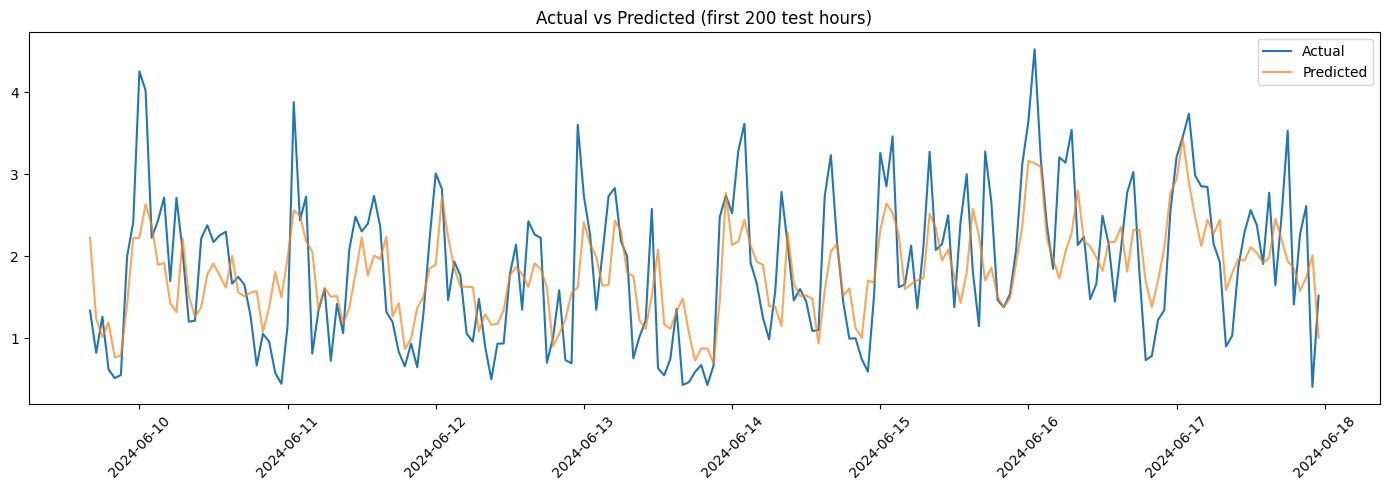

In [131]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(test_df['datetime'].values[:200], y_test.values[:200], label='Actual', linewidth=1.5)
plt.plot(test_df['datetime'].values[:200], y_pred[:200], label='Predicted', linewidth=1.5, alpha=0.7)
plt.legend()
plt.title('Actual vs Predicted (first 200 test hours)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [132]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Scaling is required for neural networks
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(hourly_df[['Usage (kW)']])

# Build sequences (predict the next hour from the previous 24 hours)
def create_sequences(data, seq_length=24):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(X), np.array(y)

SEQ_LEN = 24
X_seq, y_seq = create_sequences(scaled_data, SEQ_LEN)

# Chronological split (same 80/20)
split = int(len(X_seq) * 0.8)
X_train_lstm, X_test_lstm = X_seq[:split], X_seq[split:]
y_train_lstm, y_test_lstm = y_seq[:split], y_seq[split:]

print("X_train_lstm:", X_train_lstm.shape)
print("X_test_lstm:", X_test_lstm.shape)

X_train_lstm: (6560, 24, 1)
X_test_lstm: (1641, 24, 1)


In [133]:
# Model architecture
lstm_model = Sequential([
    LSTM(50, activation='relu', input_shape=(SEQ_LEN, 1), return_sequences=True),
    LSTM(50, activation='relu'),
    Dense(25, activation='relu'),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [134]:
history = lstm_model.fit(
    X_train_lstm, y_train_lstm,
    validation_data=(X_test_lstm, y_test_lstm),
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0064 - val_loss: 0.0107
Epoch 2/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0056 - val_loss: 0.0111
Epoch 3/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0054 - val_loss: 0.0102
Epoch 4/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0049 - val_loss: 0.0094
Epoch 5/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0047 - val_loss: 0.0087
Epoch 6/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0044 - val_loss: 0.0084
Epoch 7/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0045 - val_loss: 0.0086
Epoch 8/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0042 - val_loss: 0.0086
Epoch 9/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0040 - val_loss: 0.0074
Epoch 10/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0037 - val_loss: 0.0065
Epoch 11/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0037 - val_loss: 0.0065
Epoch 12/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/ste

In [135]:
# Generate predictions
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

# Undo the scaling (back to original kW units)
y_pred_lstm = scaler.inverse_transform(y_pred_lstm_scaled)
y_test_lstm_original = scaler.inverse_transform(y_test_lstm)

# Calculate metrics (same as for Random Forest)
mae_lstm = mean_absolute_error(y_test_lstm_original, y_pred_lstm)
rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm_original, y_pred_lstm))
smape_lstm = smape(y_test_lstm_original.flatten(), y_pred_lstm.flatten())

print(f"LSTM MAE: {mae_lstm:.4f} kW")
print(f"LSTM RMSE: {rmse_lstm:.4f} kW")
print(f"LSTM sMAPE: {smape_lstm:.2f}%")

print(f"\n--- Comparison ---")
print(f"Random Forest: MAE={mae:.4f}, RMSE={rmse:.4f}, sMAPE={smape(y_test, y_pred):.2f}%")
print(f"LSTM:          MAE={mae_lstm:.4f}, RMSE={rmse_lstm:.4f}, sMAPE={smape_lstm:.2f}%")

52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step
LSTM MAE: 0.3120 kW
LSTM RMSE: 0.5115 kW
LSTM sMAPE: 44.44%

--- Comparison ---
Random Forest: MAE=0.2656, RMSE=0.4654, sMAPE=37.58%
LSTM:          MAE=0.3120, RMSE=0.5115, sMAPE=44.44%


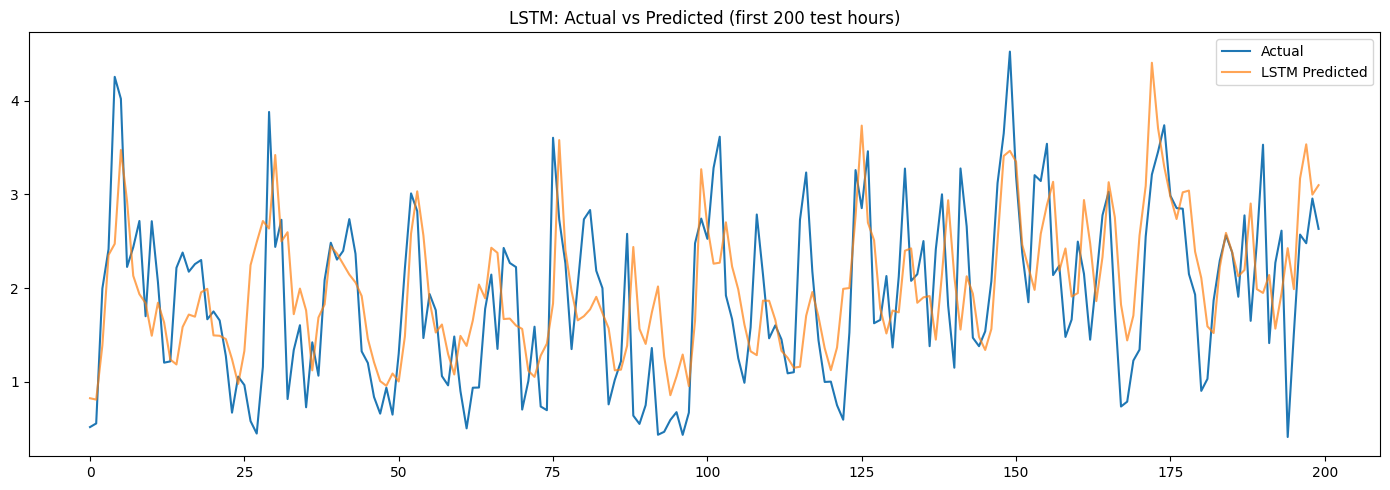

In [136]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_lstm_original[:200], label='Actual', linewidth=1.5)
plt.plot(y_pred_lstm[:200], label='LSTM Predicted', linewidth=1.5, alpha=0.7)
plt.legend()
plt.title('LSTM: Actual vs Predicted (first 200 test hours)')
plt.tight_layout()
plt.show()

In [137]:
# Build sequences using multiple features (not just Usage)
feature_set = ['Usage (kW)', 'hour', 'day_of_week', 'rolling_avg_24hr']
scaler_multi = MinMaxScaler()
scaled_multi = scaler_multi.fit_transform(hourly_df[feature_set])

def create_sequences_multi(data, target_idx=0, seq_length=24):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i+seq_length])
        y.append(data[i+seq_length, target_idx])
    return np.array(X), np.array(y)

X_multi, y_multi = create_sequences_multi(scaled_multi)
print(X_multi.shape)

(8201, 24, 4)


In [138]:
# Chronological split (same 80/20)
split_m = int(len(X_multi) * 0.8)
X_train_m, X_test_m = X_multi[:split_m], X_multi[split_m:]
y_train_m, y_test_m = y_multi[:split_m], y_multi[split_m:]

print("X_train_m:", X_train_m.shape)
print("X_test_m:", X_test_m.shape)

# Model (same architecture, only the input shape changed -- now 4 features)
lstm_model_v2 = Sequential([
    LSTM(50, activation='relu', input_shape=(SEQ_LEN, len(feature_set)), return_sequences=True),
    LSTM(50, activation='relu'),
    Dense(25, activation='relu'),
    Dense(1)
])

lstm_model_v2.compile(optimizer='adam', loss='mse')

history_v2 = lstm_model_v2.fit(
    X_train_m, y_train_m,
    validation_data=(X_test_m, y_test_m),
    epochs=20,
    batch_size=32,
    verbose=1
)

X_train_m: (6560, 24, 4)
X_test_m: (1641, 24, 4)
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


205/205 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 0.0064 - val_loss: 0.0100
Epoch 2/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0049 - val_loss: 0.0098
Epoch 3/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0047 - val_loss: 0.0094
Epoch 4/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0046 - val_loss: 0.0097
Epoch 5/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0045 - val_loss: 0.0094
Epoch 6/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0044 - val_loss: 0.0109
Epoch 7/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0043 - val_loss: 0.0080
Epoch 8/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0042 - val_loss: 0.0079
Epoch 9/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0039 - val_loss: 0.0073
Epoch 10/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0038 - val_loss: 0.0081
Epoch 11/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0037 - val_loss: 0.0076
Epoch 12/20
205/205 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0

In [139]:
# Predictions
y_pred_m_scaled = lstm_model_v2.predict(X_test_m)

# For inverse transform -- the scaler was fit on 4 columns, so build a dummy array
dummy = np.zeros((len(y_pred_m_scaled), len(feature_set)))
dummy[:, 0] = y_pred_m_scaled.flatten()  # Put predictions into the Usage column (index 0)
y_pred_m = scaler_multi.inverse_transform(dummy)[:, 0]

dummy_actual = np.zeros((len(y_test_m), len(feature_set)))
dummy_actual[:, 0] = y_test_m
y_test_m_original = scaler_multi.inverse_transform(dummy_actual)[:, 0]

# Metrics
mae_lstm_v2 = mean_absolute_error(y_test_m_original, y_pred_m)
rmse_lstm_v2 = np.sqrt(mean_squared_error(y_test_m_original, y_pred_m))
smape_lstm_v2 = smape(y_test_m_original, y_pred_m)

print(f"\n--- Final Comparison ---")
print(f"Random Forest:        MAE={mae:.4f}, RMSE={rmse:.4f}, sMAPE={smape(y_test, y_pred):.2f}%")
print(f"LSTM (univariate):    MAE={mae_lstm:.4f}, RMSE={rmse_lstm:.4f}, sMAPE={smape_lstm:.2f}%")
print(f"LSTM (multivariate):  MAE={mae_lstm_v2:.4f}, RMSE={rmse_lstm_v2:.4f}, sMAPE={smape_lstm_v2:.2f}%")

52/52 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step

--- Final Comparison ---
Random Forest:        MAE=0.2656, RMSE=0.4654, sMAPE=37.58%
LSTM (univariate):    MAE=0.3120, RMSE=0.5115, sMAPE=44.44%
LSTM (multivariate):  MAE=0.2669, RMSE=0.4489, sMAPE=39.32%


In [140]:
# Compute residuals from the Random Forest predictions (on the test set)
residuals = y_test.values - y_pred

# Statistical threshold -- a residual beyond 3 standard deviations is an anomaly
mean_res = residuals.mean()
std_res = residuals.std()
threshold = 3 * std_res

anomaly_mask = np.abs(residuals - mean_res) > threshold

print(f"Total test points: {len(residuals)}")
print(f"Anomalies detected: {anomaly_mask.sum()} ({anomaly_mask.sum()/len(residuals)*100:.2f}%)")

# Look at the dates flagged as anomalies
anomaly_dates = test_df['datetime'].values[anomaly_mask]
anomaly_actual = y_test.values[anomaly_mask]
anomaly_pred = y_pred[anomaly_mask]

results = pd.DataFrame({
    'datetime': anomaly_dates,
    'actual': anomaly_actual,
    'predicted': anomaly_pred,
    'residual': residuals[anomaly_mask]
})
print(results.head(15))

Total test points: 1645
Anomalies detected: 44 (2.67%)
              datetime    actual  predicted  residual
0  2024-06-10 00:00:00  4.254598   2.226419  2.028179
1  2024-06-10 01:00:00  4.019977   2.635022  1.384955
2  2024-06-10 06:00:00  2.713861   1.320410  1.393451
3  2024-06-12 23:00:00  3.604518   1.623958  1.980560
4  2024-06-13 12:00:00  0.638374   2.081442 -1.443068
5  2024-06-14 08:00:00  2.785422   1.153101  1.632322
6  2024-06-15 17:00:00  3.276988   1.704099  1.572889
7  2024-06-16 01:00:00  4.524162   3.133228  1.390934
8  2024-06-16 05:00:00  3.205478   1.729894  1.475584
9  2024-06-17 18:00:00  3.530262   1.940194  1.590068
10 2024-06-17 22:00:00  0.410340   2.013137 -1.602797
11 2024-06-18 16:00:00  3.325583   1.900231  1.425352
12 2024-06-18 23:00:00  4.085384   2.458585  1.626799
13 2024-06-19 00:00:00  4.777721   2.900214  1.877507
14 2024-06-19 01:00:00  4.546168   2.984229  1.561938


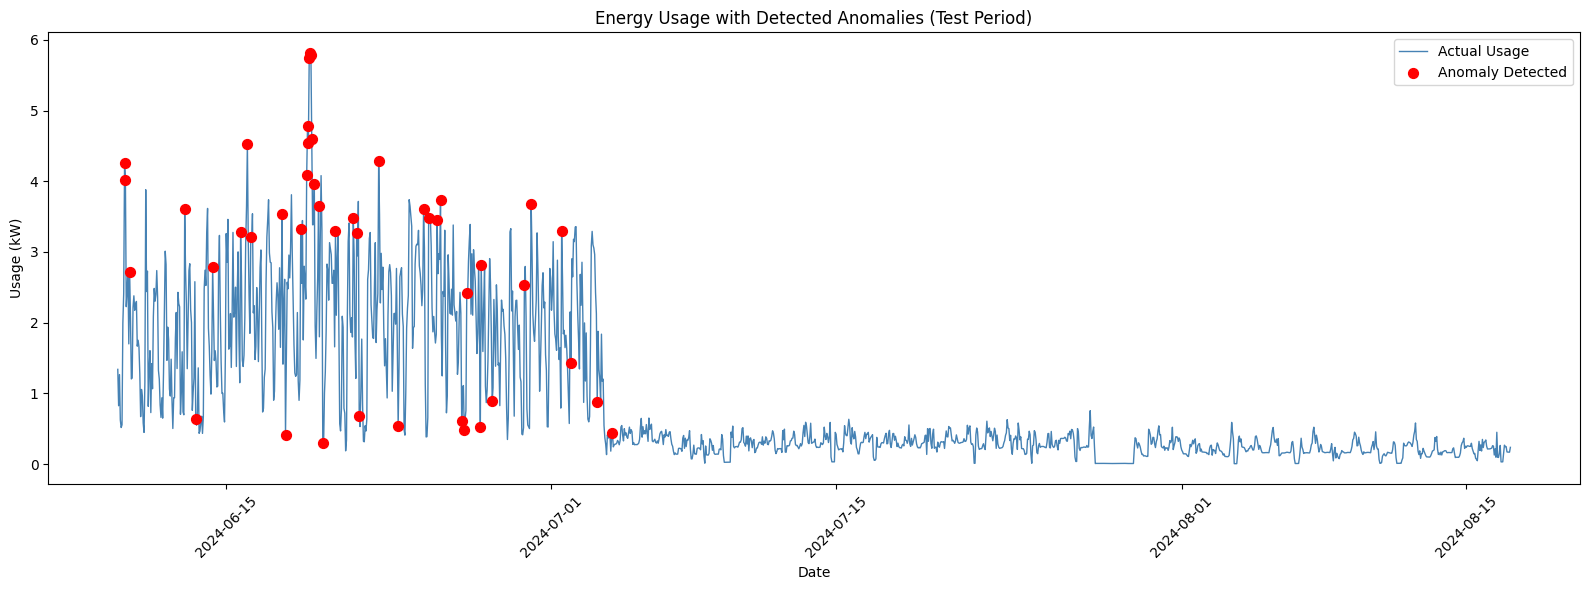

In [141]:
plt.figure(figsize=(16, 6))
plt.plot(test_df['datetime'], y_test.values, label='Actual Usage', linewidth=1, color='steelblue')
plt.scatter(anomaly_dates, anomaly_actual, color='red', s=50, zorder=5, label='Anomaly Detected')
plt.title('Energy Usage with Detected Anomalies (Test Period)')
plt.xlabel('Date')
plt.ylabel('Usage (kW)')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [142]:
def clean_and_prepare(filepath, zero_streak_threshold=10):
    """Load, clean timestamps, fix duplicates, interpolate, resample to hourly"""
    
    raw_df = pd.read_csv(filepath)
    if 'Usage..kW.' in raw_df.columns:
        raw_df = raw_df.rename(columns={'Usage..kW.': 'Usage (kW)'})
    raw_time = raw_df["datetime"].astype(str)
    
    # Duplicate-timestamp fix (same logic developed earlier)
    new_datetime = []
    i = 0
    while i < len(raw_df):
        current = raw_time.iloc[i]
        j = i + 1
        while j < len(raw_df) and raw_time.iloc[j] == current:
            j += 1
        count = j - i
        base_time = pd.to_datetime(current, format="mixed")
        for second in range(count):
            new_datetime.append(base_time + pd.Timedelta(seconds=second))
        i = j
    
    df = raw_df.copy()
    df["datetime"] = new_datetime
    
    # Zero-streak detection (sensor downtime)
    df['is_zero'] = df['Usage (kW)'] == 0
    df['zero_streak'] = df['is_zero'].groupby((~df['is_zero']).cumsum()).cumsum()
    suspicious = df['zero_streak'] >= zero_streak_threshold
    df.loc[suspicious, 'Usage (kW)'] = np.nan
    
    # Interpolate + resample
    df = df.set_index('datetime')
    df['Usage (kW)'] = df['Usage (kW)'].interpolate(method='time')
    hourly = df[['Usage (kW)']].resample('h').mean().reset_index()
    
    return hourly


def add_features(hourly_df):
    """Lag features + rolling average"""
    df = hourly_df.copy()
    df['hour'] = df['datetime'].dt.hour
    df['day_of_week'] = df['datetime'].dt.dayofweek
    df['month'] = df['datetime'].dt.month
    df['usage_lag_1hr'] = df['Usage (kW)'].shift(1)
    df['usage_lag_24hr'] = df['Usage (kW)'].shift(24)
    df['usage_lag_168hr'] = df['Usage (kW)'].shift(168)
    df['rolling_avg_24hr'] = df['Usage (kW)'].rolling(24).mean()
    return df.dropna().reset_index(drop=True)


def train_and_evaluate(df, house_name):
    """Train RF, detect anomalies, return results"""
    feature_cols = ['hour', 'day_of_week', 'month', 'usage_lag_1hr', 
                     'usage_lag_24hr', 'usage_lag_168hr', 'rolling_avg_24hr']
    target_col = 'Usage (kW)'
    
    split_idx = int(len(df) * 0.8)
    train_df, test_df = df.iloc[:split_idx], df.iloc[split_idx:]
    
    X_train, y_train = train_df[feature_cols], train_df[target_col]
    X_test, y_test = test_df[feature_cols], test_df[target_col]
    
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    smape_val = smape(y_test.values, y_pred)
    
    # Anomaly detection
    residuals = y_test.values - y_pred
    threshold = 3 * residuals.std()
    anomaly_mask = np.abs(residuals - residuals.mean()) > threshold
    
    print(f"[{house_name}] MAE={mae:.4f} | sMAPE={smape_val:.2f}% | Anomalies={anomaly_mask.sum()} ({anomaly_mask.sum()/len(residuals)*100:.2f}%)")
    
    return {'house': house_name, 'model': model, 'mae': mae, 'smape': smape_val, 
            'test_df': test_df, 'y_test': y_test, 'y_pred': y_pred, 'anomaly_mask': anomaly_mask}

In [143]:
karachi_files = {
    'House38': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House38.csv',
    'House39': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House39.csv',
    'House40': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House40.csv',
}

all_results = {}

for house_name, filepath in karachi_files.items():
    hourly = clean_and_prepare(filepath)
    featured = add_features(hourly)
    result = train_and_evaluate(featured, house_name)
    all_results[house_name] = result

[House38] MAE=0.2656 | sMAPE=37.58% | Anomalies=44 (2.67%)
[House39] MAE=0.3531 | sMAPE=41.68% | Anomalies=16 (0.93%)
[House40] MAE=0.3417 | sMAPE=31.39% | Anomalies=35 (2.04%)


In [144]:
Pakistan_Cities_files = {
    'Karachi_H38': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House38.csv',
    'Karachi_H39': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House39.csv',
    'Karachi_H40': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Karachi/karachi_House40.csv',
    'Lahore_H7': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Lahore/lahore_House7.csv',
    'Lahore_H8': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Lahore/lahore_House8.csv',
    'Lahore_H9': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Lahore/lahore_House9.csv',
    'Peshawar_H26': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Peshawar/peshawar_House26.csv',
    'Peshawar_H29': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Peshawar/peshawar_House29.csv',
    'Peshawar_H30': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Peshawar/peshawar_House30.csv',
    'Multan_H18': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Multan/multan_House18.csv',
    'Multan_H19': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Multan/multan_House19.csv',
    'Multan_H20': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Multan/multan_House20.csv',
    'Skardu_H56': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Skardu/skardu_House56.csv',
    'Skardu_H57': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Skardu/skardu_House57.csv',
    'Skardu_H59': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Skardu/skardu_House59.csv',
    'Islamabad_H48': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Islamabad/islamabad_House48.csv',
    'Islamabad_H49': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Islamabad/islamabad_House49.csv',
    'Islamabad_H50': '/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset/Islamabad/islamabad_House50.csv',
}

all_results = {}

for house_name, filepath in Pakistan_Cities_files.items():
    try:
        hourly = clean_and_prepare(filepath)
        featured = add_features(hourly)
        result = train_and_evaluate(featured, house_name)
        all_results[house_name] = result
    except Exception as e:
        print(f"[{house_name}] FAILED: {e}")

[Karachi_H38] MAE=0.2656 | sMAPE=37.58% | Anomalies=44 (2.67%)
[Karachi_H39] MAE=0.3531 | sMAPE=41.68% | Anomalies=16 (0.93%)
[Karachi_H40] MAE=0.3417 | sMAPE=31.39% | Anomalies=35 (2.04%)
[Lahore_H7] MAE=0.2698 | sMAPE=32.08% | Anomalies=34 (2.12%)
[Lahore_H8] MAE=0.2982 | sMAPE=17.55% | Anomalies=34 (1.98%)
[Lahore_H9] MAE=0.3493 | sMAPE=45.18% | Anomalies=33 (1.92%)
[Peshawar_H26] MAE=0.2943 | sMAPE=33.48% | Anomalies=26 (1.51%)
[Peshawar_H29] MAE=0.2424 | sMAPE=76.12% | Anomalies=22 (1.30%)
[Peshawar_H30] MAE=0.6285 | sMAPE=49.44% | Anomalies=29 (1.71%)
[Multan_H18] MAE=0.2295 | sMAPE=25.26% | Anomalies=40 (2.33%)
[Multan_H19] MAE=0.1980 | sMAPE=27.20% | Anomalies=37 (2.15%)
[Multan_H20] MAE=0.1512 | sMAPE=33.16% | Anomalies=38 (2.23%)
[Skardu_H56] MAE=0.1944 | sMAPE=61.86% | Anomalies=18 (1.40%)
[Skardu_H57] MAE=0.4789 | sMAPE=126.03% | Anomalies=59 (2.64%)
[Skardu_H59] MAE=0.0472 | sMAPE=70.32% | Anomalies=22 (1.40%)
[Islamabad_H48] MAE=0.3376 | sMAPE=34.24% | Anomalies=36 (2.09%

In [146]:
summary = pd.DataFrame([
    {'house': k, 'city': k.split('_')[0], 'mae': v['mae'], 'smape': v['smape'], 
     'anomaly_pct': v['anomaly_mask'].sum()/len(v['anomaly_mask'])*100}
    for k, v in all_results.items()
])

print("--- Full Results (sorted by MAE) ---")
print(summary.sort_values('mae').to_string(index=False))

city_avg = summary.groupby('city')[['mae', 'smape', 'anomaly_pct']].mean().sort_values('mae')
print("\n--- City-wise Average ---")
print(city_avg)

--- Full Results (sorted by MAE) ---
        house      city      mae      smape  anomaly_pct
   Skardu_H59    Skardu 0.047211  70.315332     1.402167
   Multan_H20    Multan 0.151215  33.162377     2.228739
   Skardu_H56    Skardu 0.194413  61.860786     1.401869
   Multan_H19    Multan 0.198007  27.204085     2.152414
   Multan_H18    Multan 0.229532  25.260482     2.326934
 Peshawar_H29  Peshawar 0.242431  76.115059     1.297170
  Karachi_H38   Karachi 0.265609  37.584182     2.674772
    Lahore_H7    Lahore 0.269766  32.077588     2.119701
 Peshawar_H26  Peshawar 0.294314  33.475881     1.512507
    Lahore_H8    Lahore 0.298162  17.549843     1.977894
Islamabad_H48 Islamabad 0.337593  34.237293     2.094241
  Karachi_H40   Karachi 0.341670  31.389894     2.042007
    Lahore_H9    Lahore 0.349302  45.176564     1.919721
  Karachi_H39   Karachi 0.353136  41.677538     0.928074
Islamabad_H49 Islamabad 0.375559  60.193908     2.094241
Islamabad_H50 Islamabad 0.457022  38.954549     1.5

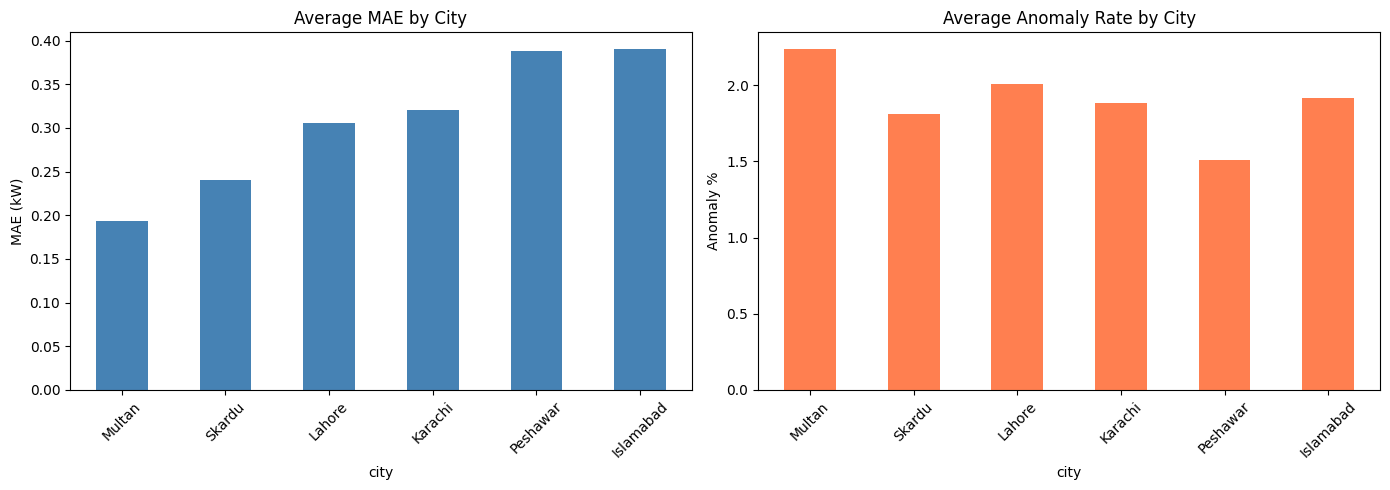

In [147]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

city_avg['mae'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Average MAE by City')
axes[0].set_ylabel('MAE (kW)')
axes[0].tick_params(axis='x', rotation=45)

city_avg['anomaly_pct'].plot(kind='bar', ax=axes[1], color='coral')
axes[1].set_title('Average Anomaly Rate by City')
axes[1].set_ylabel('Anomaly %')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [148]:
# Forecasting Model Comparison

model_comparison = pd.DataFrame({
    'Model': [
        'Random Forest',
        'LSTM (Univariate)',
        'LSTM (Multivariate)'
    ],
    'MAE (kW)': [
        mae,
        mae_lstm,
        mae_lstm_v2
    ],
    'RMSE (kW)': [
        rmse,
        rmse_lstm,
        rmse_lstm_v2
    ],
    'sMAPE (%)': [
        smape(y_test, y_pred),
        smape_lstm,
        smape_lstm_v2
    ]
})

print(model_comparison.round(4))

                 Model  MAE (kW)  RMSE (kW)  sMAPE (%)
0        Random Forest    0.2656     0.4654    37.5842
1    LSTM (Univariate)    0.3120     0.5115    44.4363
2  LSTM (Multivariate)    0.2669     0.4489    39.3171
